<a href="https://colab.research.google.com/github/haejeg/BuffsMarket/blob/main/CU_ROVER26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Dependencies
!pip install roboflow
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 88.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 135.9 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.90
    Uninstalling opencv-python-headless-4.13.0.90:
      Successfully uninstalled opencv-python-headless-4.13.0.90
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 70.0 MB/s eta 0:00:00


In [ ]:
import sys
print(sys.executable)
for path in sys.path:
    print(path)
from ultralytics import YOLO
import os
from IPython.display import display, Image
from IPython import display
display.clear_output()

In [ ]:
from roboflow import Roboflow
from google.colab import userdata

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace().project("hammerfinder")
dataset = project.version(2).download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to hammerfinder-2 in yolov8:: 100%|██████████| 37/37 [00:00<00:00, 7723.55it/s]


In [11]:
# Training Set
!yolo train model=yolov8n.pt data=./hammerfinder-2/data.yaml epochs=100 imgsz=640 batch=16 project=hammerfinder_results name=yolov8n_hammerfinder

Traceback (most recent call last):
  File "<frozen importlib._bootstrap>", line 1331, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 935, in _load_unlocked
  File "<frozen importlib._bootstrap_external>", line 999, in exec_module
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  File "/usr/local/lib/python3.12/dist-packages/torch/onnx/ops/__init__.py", line 23, in <module>
    from torch.onnx.ops import _impl, _symbolic_impl
  File "/usr/local/lib/python3.12/dist-packages/torch/onnx/ops/_impl.py", line 251, in <module>
    @_onnx_op("Attention", 23)
     ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/onnx/ops/_impl.py", line 33, in decorator
    torch_op = torch.library.custom_op(
               ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/_library/custom_ops.py", line 153, in inner
    result = CustomOpDef(namespace, opname, schema_str, fn, tags)
             ^^^^

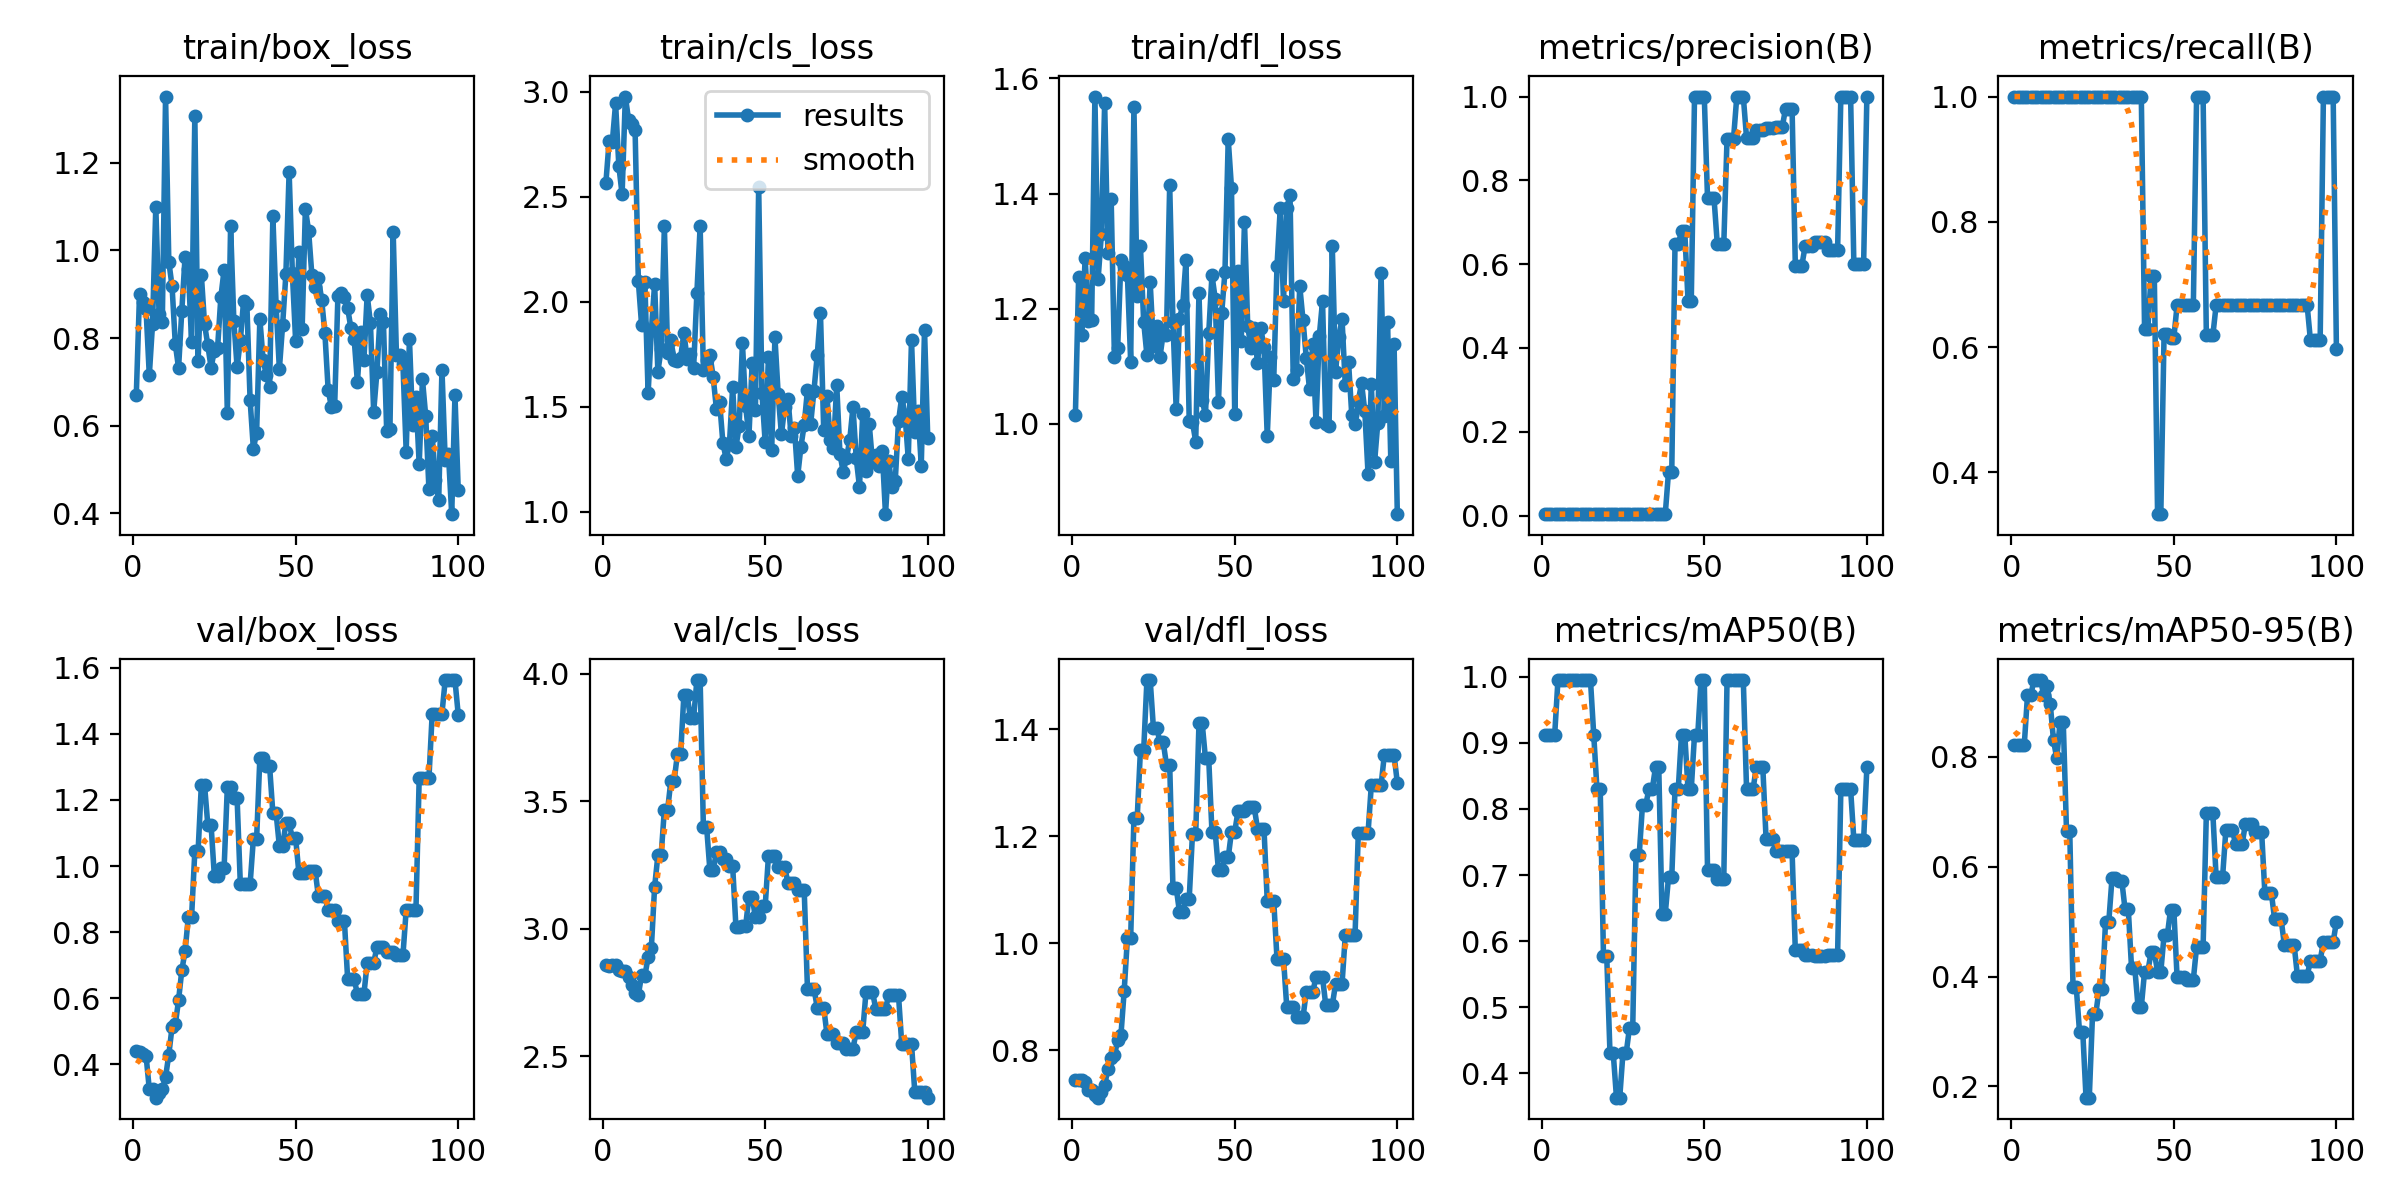

In [7]:
Image(filename=f'/content/runs/detect/hammerfinder_results/yolov8n_hammerfinder/results.png', width=600)

In [9]:
# Validation Set
!yolo task=detect mode=val model=/content/runs/detect/hammerfinder_results/yolov8n_hammerfinder/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.4.10 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1416.6±580.4 MB/s, size: 42.0 KB)
val: Scanning /content/hammerfinder-2/valid/labels.cache... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 629.1Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.1it/s 0.2s
                   all          3          3    0.00333          1      0.995       0.94
Speed: 0.8ms preprocess, 21.8ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


In [12]:
!yolo task=detect mode=predict model=/content/runs/detect/hammerfinder_results/yolov8n_hammerfinder/weights/best.pt data={dataset.location}/data.yaml

WARNING ⚠️ 'source' argument is missing. Using default 'source=/usr/local/lib/python3.12/dist-packages/ultralytics/assets'.
Ultralytics 8.4.10 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs

image 1/2 /usr/local/lib/python3.12/dist-packages/ultralytics/assets/bus.jpg: 640x480 (no detections), 88.3ms
image 2/2 /usr/local/lib/python3.12/dist-packages/ultralytics/assets/zidane.jpg: 384x640 (no detections), 60.5ms
Speed: 2.7ms preprocess, 74.4ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


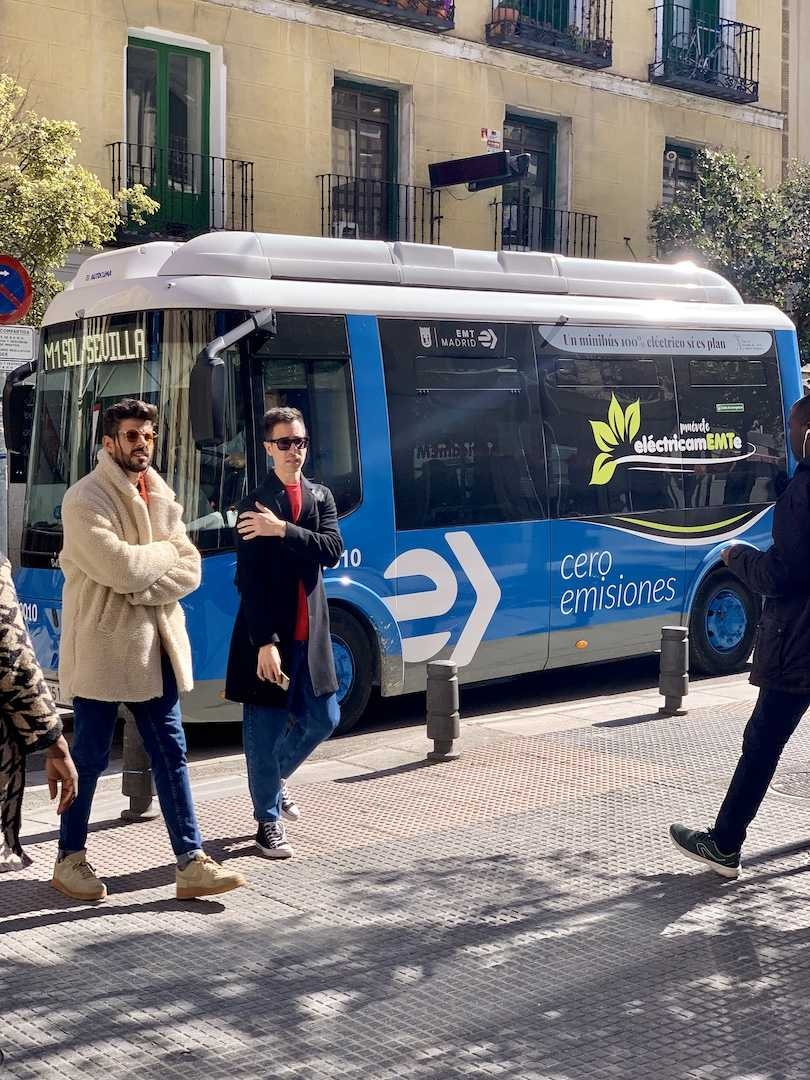

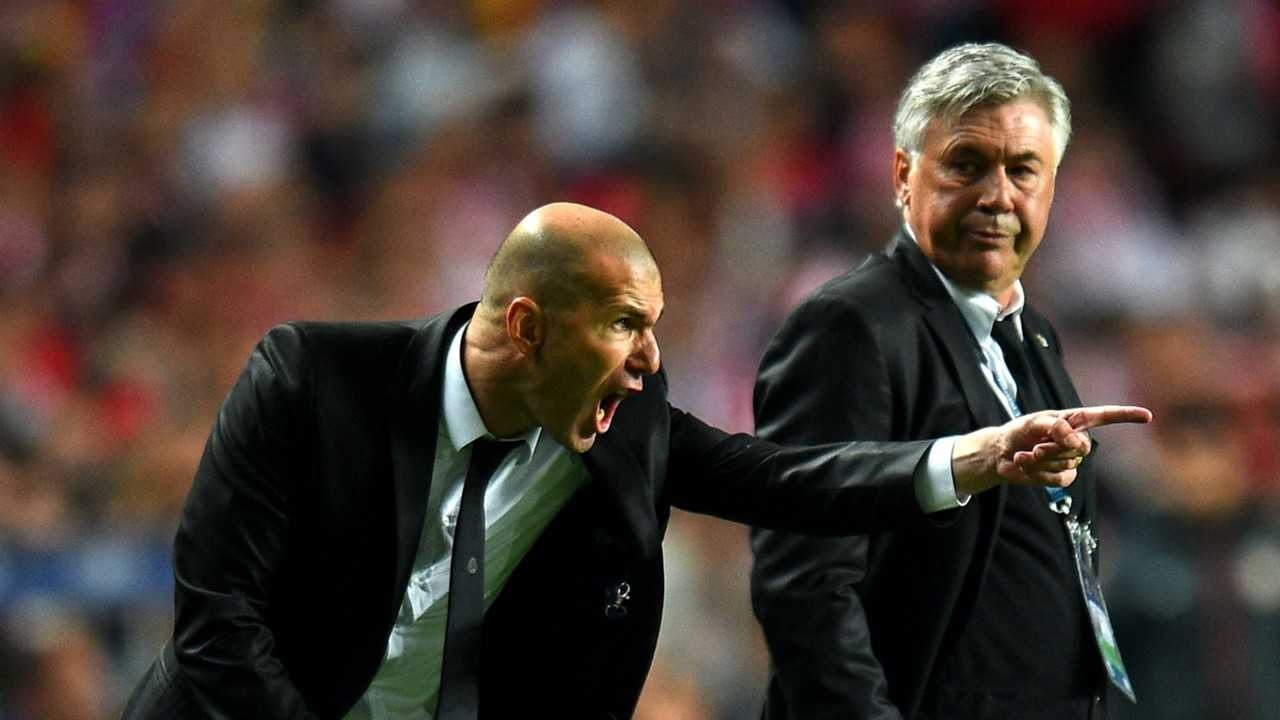

In [15]:
import glob
from IPython.display import Image, display

# Put predict files into predict folder.
for image_path in glob.glob('/content/runs/detect/predict/*.jpg')[:3]:
      display(Image(filename=image_path, height=300))
      print('\n')